## Handling Categorical Missing data

### 1.Frequent Value Imputation
### 2.Missing Categorical Imputation


#### 1.Frequent Value Imputation When to use..?
##### Missing Completely at Random
##### Missing Data Is Less than Or equal to 5%

##### Advantages:Easy to apply

##### Disadvantage:Change the distribution of data

#### 2.Missing Categorical Imputation
##### Advantages:USe Arbitary Value
##### Disadvantages:Generates Randommness inn Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

In [3]:
df=pd.read_csv("train.csv",usecols=['GarageQual','FireplaceQu','SalePrice'])

df.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [7]:
df.isnull().mean()*100

#FireplaceQ has most Null values in it which is 47%
#GarageQual has most Null values equal to 5.5%

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

<Axes: xlabel='GarageQual'>

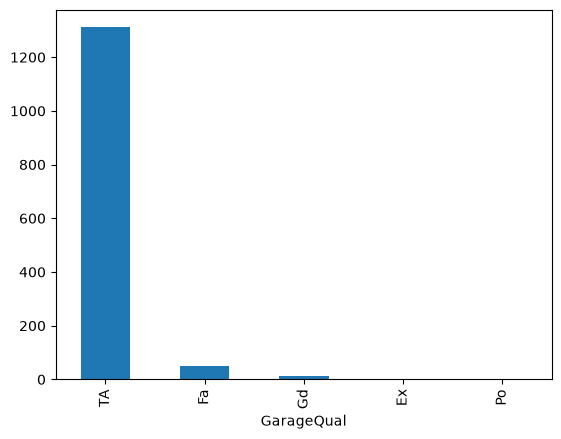

In [8]:
df["GarageQual"].value_counts().plot(kind="bar")

In [9]:
df["GarageQual"].mode()

# We can see that for Garage Qual Mode is TA

0    TA
Name: GarageQual, dtype: str

Text(0.5, 1.0, 'GarageQual')

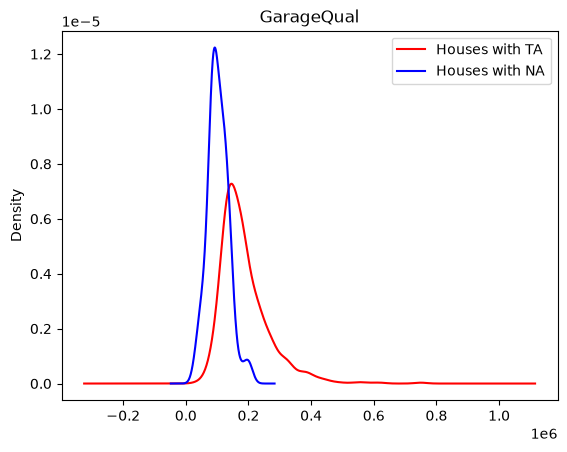

In [10]:
fig=plt.figure()
ax=fig.add_subplot(111)

df[df["GarageQual"]=="TA"]["SalePrice"].plot(kind="kde",color="red",ax=ax)

df[df["GarageQual"].isnull()]["SalePrice"].plot(kind="kde",color="blue",ax=ax)
lines, labels = ax.get_legend_handles_labels()
labels = ['Houses with TA', 'Houses with NA']
ax.legend(lines, labels, loc='best')

plt.title('GarageQual')

#From the below graph we can see the difference between TA values And Null Values

In [11]:
temp=df[df["GarageQual"]=="TA"]["SalePrice"]

In [12]:
df["GarageQual"].fillna("TA",inplace=True)

C:\Users\Admin\AppData\Local\Temp\ipykernel_11292\1808853980.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["GarageQual"].fillna("TA",inplace=True)


0       TA
1       TA
2       TA
3       TA
4       TA
        ..
1455    TA
1456    TA
1457    TA
1458    TA
1459    TA
Name: GarageQual, Length: 1460, dtype: str

<Axes: xlabel='GarageQual'>

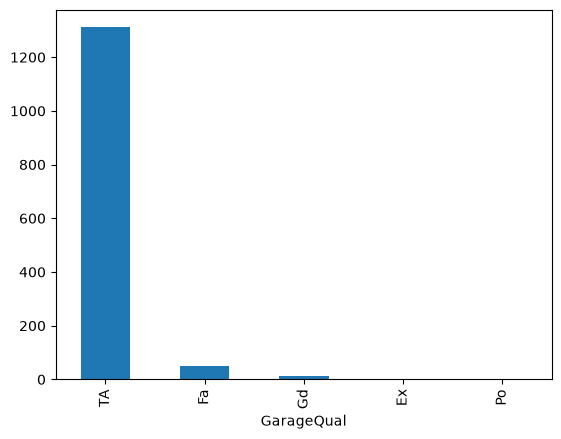

In [13]:
df["GarageQual"].value_counts().plot(kind="bar")

Text(0.5, 1.0, 'GarageQual')

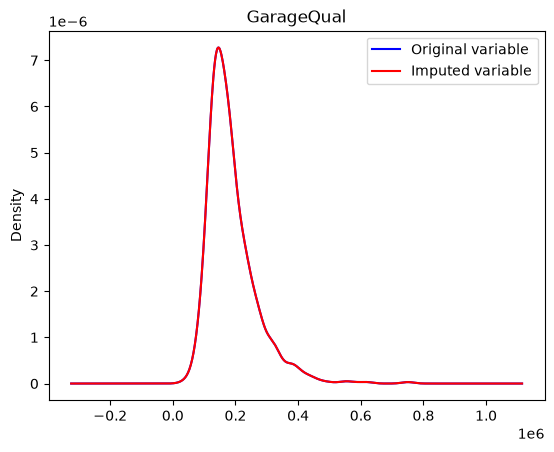

In [14]:
fig=plt.figure()
ax=plt.subplot(111)
temp.plot(kind="kde",ax=ax,color="blue")
df[df['GarageQual'] == 'TA']['SalePrice'].plot(kind='kde', ax=ax, color='red')
lines, labels = ax.get_legend_handles_labels()
labels = ['Original variable', 'Imputed variable']
ax.legend(lines, labels, loc='best')

# add title
plt.title('GarageQual')

<Axes: xlabel='FireplaceQu'>

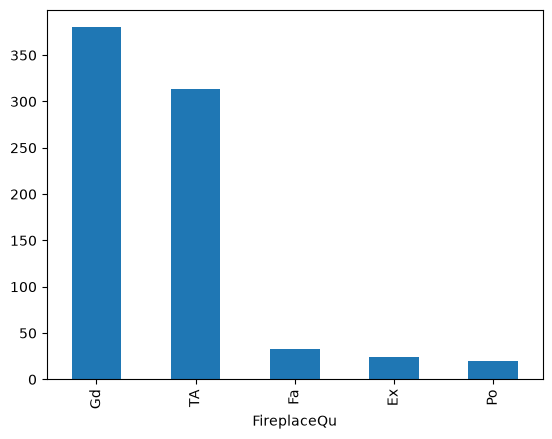

In [15]:
df["FireplaceQu"].value_counts().plot(kind="bar")

In [16]:
df["FireplaceQu"].mode()

0    Gd
Name: FireplaceQu, dtype: str

In [17]:
temp=df[df["FireplaceQu"]=='GD']['SalePrice']

In [18]:
df["FireplaceQu"].fillna("GD",inplace=True)

C:\Users\Admin\AppData\Local\Temp\ipykernel_11292\979801240.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["FireplaceQu"].fillna("GD",inplace=True)


0       GD
1       TA
2       TA
3       Gd
4       TA
        ..
1455    TA
1456    TA
1457    Gd
1458    GD
1459    GD
Name: FireplaceQu, Length: 1460, dtype: str

<Axes: xlabel='FireplaceQu'>

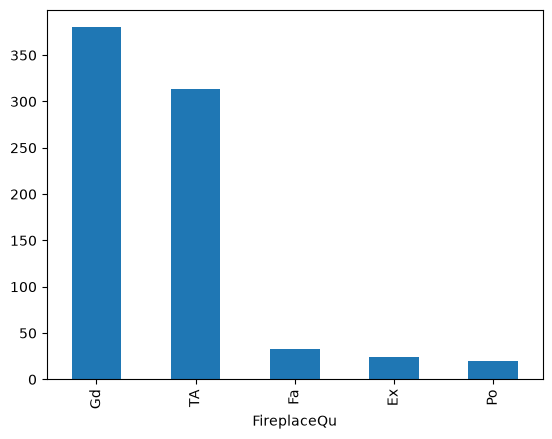

In [19]:
df["FireplaceQu"].value_counts().plot(kind="bar")

ValueError: zero-size array to reduction operation fmax which has no identity

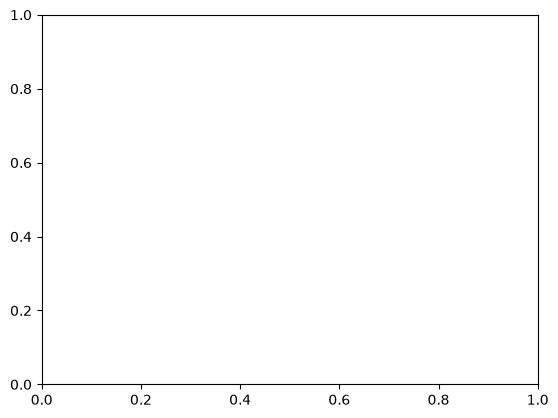

In [21]:
fig = plt.figure()
ax = fig.add_subplot(111)


temp.plot(kind='kde', ax=ax)

# distribution of the variable after imputation
df[df['FireplaceQu'] == 'Gd']['SalePrice'].plot(kind='kde', ax=ax, color='red')

lines, labels = ax.get_legend_handles_labels()
labels = ['Original variable', 'Imputed variable']
ax.legend(lines, labels, loc='best')

# add title
plt.title('FireplaceQu')

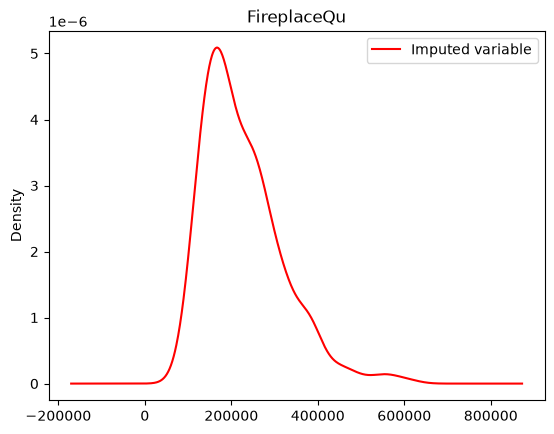

In [22]:
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(111)

# Plot original variable if temp isn't empty
if not temp.empty:
    temp.plot(kind='kde', ax=ax, label='Original variable')

# Check if the filtered imputed subset has data before plotting
imputed_subset = df[df['FireplaceQu'] == 'Gd']['SalePrice']
if not imputed_subset.empty:
    imputed_subset.plot(kind='kde', ax=ax, color='red', label='Imputed variable')
else:
    print("Warning: No rows found for 'Gd' in FireplaceQu!")

ax.legend(loc='best')
plt.title('FireplaceQu')
plt.show()

## Imputation Using Sklearn

In [23]:
X_train,X_test,Y_train,Y_test=train_test_split(df.drop(columns=["SalePrice"]),df["SalePrice"],test_size=0.2,random_state=42)

imputer=SimpleImputer(strategy="most_frequent")

X_train=imputer.fit_transform(X_train)

X_test=imputer.transform(X_test)

imputer.statistics_

array(['Gd', 'TA'], dtype=object)